# 01 · ETL, validação e engenharia de atributos

**Problema (Etapa 1).** Regressão: prever a **resistência à compressão do concreto (MPa)** a partir da composição da mistura e da idade do corpo de prova.

| Item | Definição |
|---|---|
| Fonte / licença | UCI Machine Learning Repository – *Concrete Compressive Strength* (Yeh, 1998), CC BY 4.0 |
| Unidade de observação | um corpo de prova de concreto (mistura + idade de ensaio) |
| Variável-alvo | `resistencia` (MPa) |
| Atributos | cimento, escória, cinza volante, água, superplastificante, agregado graúdo, agregado miúdo (kg/m³) e idade (dias) |
| Métrica principal | **MAE** (MPa): interpretável na unidade do problema e robusta a poucos valores extremos |
| Particionamento | Cerca de 20% dos grupos de traços no **teste reservado**, 15% na **validação fixa** e 65% no treino em **4 lotes**. As diferentes idades do mesmo grupo ficam na mesma partição. |
| Limitações | dataset pequeno (1.005 amostras únicas), de laboratório; não há ordem temporal real, por isso a chegada de dados é simulada por lotes |

Este notebook incorpora o **próximo lote não processado**, sem duplicação, e gera o `cycle_id` e o `data_version` do ciclo.

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.utils import preparar_ambiente, carregar_config, carregar_contexto, salvar_contexto, dir_evidencias, configurar_mlflow
preparar_ambiente()
cfg = carregar_config()
pd.set_option("display.width", 160)

In [2]:
from src.ingestao import (carregar_estado, salvar_estado, proximo_lote, carregar_treino_acumulado,
                          salvar_treino_acumulado, versao_dados)
from src.preprocessamento import diagnostico, limpar_lote, criar_atributos, ATRIBUTOS_DERIVADOS
from src.drift import detectar_drift
from src.utils import novo_cycle_id, gatilho_execucao, DIR_CICLO
import shutil

# área temporária do ciclo começa vazia
if DIR_CICLO.exists():
    shutil.rmtree(DIR_CICLO)

estado = carregar_estado(cfg)
lote = proximo_lote(cfg, estado)
cycle_id = novo_cycle_id()
ev = dir_evidencias(cycle_id)
print("cycle_id:", cycle_id)
print("Lotes já incorporados:", estado["lotes_processados"])
print("Próximo lote:", lote.name if lote else "nenhum (ciclo reutiliza os dados atuais)")

cycle_id: c20261124T230002Z-local
Lotes já incorporados: ['lote_01.csv', 'lote_02.csv']
Próximo lote: lote_03.csv


## Diagnóstico do lote recebido (antes do tratamento)

In [3]:
treino_anterior = carregar_treino_acumulado(cfg)
if lote is not None:
    bruto = pd.read_csv(lote)
    diag_antes = diagnostico(bruto, cfg)
    print(f"{lote.name}: {len(bruto)} linhas | duplicadas no lote: {bruto.duplicated().sum()}")
    display(diag_antes)
    diag_antes.to_csv(ev / "diagnostico_lote_antes.csv", index=False)
else:
    bruto, diag_antes = None, None

lote_03.csv: 106 linhas | duplicadas no lote: 0


,coluna,ausentes,fora_da_faixa,outliers_iqr,min,mediana,max
0,cimento,0,0,0,116.00,252.05,540.0
1,escoria,0,0,0,0.00,19.50,237.5
2,cinza_volante,0,0,0,0.00,91.50,182.0
3,agua,0,1,3,-1.00,183.85,246.9
4,superplastificante,0,0,0,0.00,7.25,23.4
5,agregado_graudo,0,0,0,801.00,964.10,1125.0
6,agregado_miudo,0,0,1,594.00,787.15,992.6
7,idade,0,0,10,3.00,28.00,56.0
8,resistencia,0,0,7,6.28,31.71,79.4


## Validação e limpeza

Regras (definidas em `config.yaml`):
- **Esquema**: todas as colunas esperadas devem existir; caso contrário o ciclo falha (e nada é promovido).
- **Faixas físicas plausíveis**: linhas fora das faixas são rejeitadas (ex.: água negativa).
- **Duplicatas**: removidas dentro do lote e em relação ao que já foi incorporado (hash por linha).
- **Ausentes**: alvo e ingredientes usados para agrupar o traço são obrigatórios. Outros valores, como o superplastificante, são **imputados pela mediana dentro do Pipeline**, ajustado só no treino.
- **Outliers (IQR)**: apenas reportados. Idades de 180–365 dias e resistências altas são fisicamente reais; removê-las tiraria do modelo justamente os casos de longa idade.

In [4]:
if lote is not None:
    limpo, rel = limpar_lote(bruto, treino_anterior, cfg)
    display(pd.DataFrame([rel]).T.rename(columns={0: "linhas"}))
else:
    limpo, rel = None, {"linhas_recebidas": 0, "linhas_aceitas": 0}

,linhas
linhas_recebidas,106
removidas_alvo_ausente,0
removidas_traco_incompleto,0
removidas_fora_da_faixa,1
removidas_duplicadas_no_lote,0
removidas_ja_incorporadas,5
ausentes_para_imputacao,0
linhas_aceitas,100


## Monitoramento de drift do lote novo (recurso adicional – critério 10)
Compara cada variável do lote novo com o treino acumulado (teste KS, α = 0,05).

,variavel,ks_estatistica,p_valor,media_referencia,media_lote,drift
0,agregado_graudo,0.1994,0.002540,975.184,955.423,True
1,agua,0.1316,0.106915,180.005,183.492,False
2,idade,0.1226,0.156842,22.378,24.410,False
3,resistencia,0.0895,0.498899,32.675,34.047,False
4,cinza_volante,0.0882,0.516196,62.900,70.841,False
5,cimento,0.0876,0.526236,285.547,270.563,False
6,escoria,0.0731,0.743281,62.364,68.684,False
7,agregado_miudo,0.0533,0.962915,775.065,778.055,False
8,superplastificante,0.0417,0.997547,6.425,6.609,False


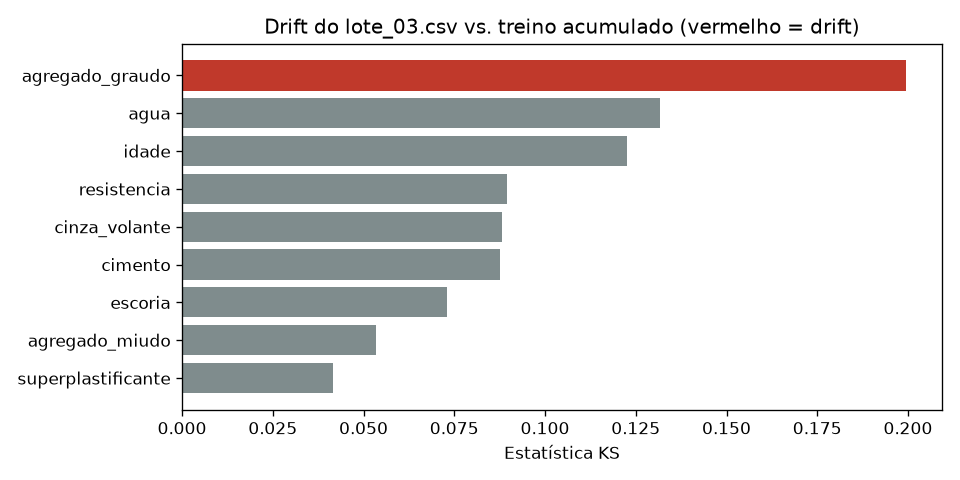

1/9 variáveis com drift (KS, p<0.05)


In [5]:
drift_resumo, drift_alerta, tabela_drift = None, False, None
if lote is not None and treino_anterior is not None and len(limpo):
    cols = cfg["dados"]["atributos_originais"] + [cfg["dados"]["alvo"]]
    tabela_drift, frac, drift_alerta = detectar_drift(treino_anterior, limpo, cols, cfg)
    n_drift = int(tabela_drift["drift"].sum())
    drift_resumo = f"{n_drift}/{len(cols)} variáveis com drift (KS, p<{cfg['drift']['alpha']})" + (" – ALERTA" if drift_alerta else "")
    display(tabela_drift)
    tabela_drift.to_csv(ev / "drift.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    cores = ["#c0392b" if d else "#7f8c8d" for d in tabela_drift["drift"]]
    ax.barh(tabela_drift["variavel"], tabela_drift["ks_estatistica"], color=cores)
    ax.invert_yaxis(); ax.set_xlabel("Estatística KS"); ax.set_title(f"Drift do {lote.name} vs. treino acumulado (vermelho = drift)")
    fig.tight_layout(); fig.savefig(ev / "drift.png", dpi=120); plt.close(fig)
    display(Image(str(ev / "drift.png")))
    print(drift_resumo)
else:
    print("Drift não avaliado (primeiro ciclo ou sem dados novos).")

## Incorporação, versionamento dos dados e diagnóstico depois

In [6]:
if lote is not None:
    treino = limpo if treino_anterior is None else pd.concat([treino_anterior, limpo], ignore_index=True)
    salvar_treino_acumulado(cfg, treino)
    estado["lotes_processados"].append(lote.name)
else:
    if treino_anterior is None:
        raise RuntimeError("Não há lotes nem treino acumulado: nada para processar.")
    treino = treino_anterior

data_version = versao_dados(treino, estado["lotes_processados"])
estado["ciclos"].append({"cycle_id": cycle_id, "lote": lote.name if lote else None, "data_version": data_version})
salvar_estado(cfg, estado)

diag_depois = diagnostico(treino, cfg)
diag_depois.to_csv(ev / "diagnostico_treino_depois.csv", index=False)
print(f"Treino acumulado: {len(treino)} linhas | data_version = {data_version}")
display(diag_depois)
print("Atributos derivados:", ATRIBUTOS_DERIVADOS)
display(criar_atributos(treino).head())

Treino acumulado: 542 linhas | data_version = v3-c6be3d56


,coluna,ausentes,fora_da_faixa,outliers_iqr,min,mediana,max
0,cimento,0,0,0,102.00,273.900,540.00
1,escoria,0,0,2,0.00,15.000,359.40
2,cinza_volante,0,0,0,0.00,79.000,200.10
3,agua,0,0,9,126.60,184.000,247.00
4,superplastificante,3,0,0,0.00,7.000,23.40
5,agregado_graudo,0,0,0,801.00,967.550,1145.00
6,agregado_miudo,0,0,4,594.00,781.500,992.60
7,idade,0,0,0,1.00,28.000,56.00
8,resistencia,0,0,12,4.57,31.495,79.99


Atributos derivados: ['relacao_agua_cimento', 'aglomerante_total', 'relacao_agua_aglomerante', 'log_idade']


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade,resistencia,relacao_agua_cimento,aglomerante_total,relacao_agua_aglomerante,log_idade
0,389.9,189.0,0.0,145.9,22.0,944.7,755.8,28,74.50,0.374199,578.9,0.252030,3.367296
1,272.8,181.9,0.0,185.7,0.0,1012.4,714.3,28,31.38,0.680718,454.7,0.408401,3.367296
2,222.4,0.0,96.7,189.3,4.5,967.1,870.3,3,11.58,0.851169,319.1,0.593231,1.386294
3,170.3,155.5,0.0,185.7,0.0,1026.6,724.3,28,25.73,1.090429,325.8,0.569982,3.367296
4,425.0,106.3,0.0,151.4,18.6,936.0,803.7,28,61.80,0.356235,531.3,0.284961,3.367296


In [7]:
mlflow = configurar_mlflow(cfg)
with mlflow.start_run(run_name=f"etl_{cycle_id}") as run:
    mlflow.set_tags({"cycle_id": cycle_id, "data_version": data_version, "etapa": "etl", "gatilho": gatilho_execucao()})
    mlflow.log_params({"lote": lote.name if lote else "nenhum", "lotes_incorporados": ",".join(estado["lotes_processados"])})
    mlflow.log_metrics({"linhas_treino": len(treino), **{k: v for k, v in rel.items() if isinstance(v, int)}})
    if tabela_drift is not None:
        mlflow.log_metrics({"drift_variaveis": int(tabela_drift["drift"].sum()), "drift_alerta": int(drift_alerta)})
    for arq in ev.glob("*"):
        mlflow.log_artifact(str(arq), artifact_path="etl")

salvar_contexto({
    "cycle_id": cycle_id, "data_version": data_version, "lote": lote.name if lote else None,
    "n_treino": len(treino), "gatilho": gatilho_execucao(), "etl": rel,
    "drift_resumo": drift_resumo, "drift_alerta": bool(drift_alerta), "run_etl": run.info.run_id,
})
print("Contexto do ciclo salvo.")

Contexto do ciclo salvo.
